# Interpretación del modelo v2

El objetivo de este notebook es explicar **por qué** el modelo asigna a cada vendedora el riesgo de churn que le asigna. El modelo es el elegido en `04_modelado/modelado_v2.ipynb` y evaluado en `05_evaluacion/evaluacion_v2.ipynb`; aquí no se decide nada.

Usamos SHAP, que reparte la predicción de cada vendedora entre sus variables. Por ejemplo, si el modelo le da 65 % de riesgo a una vendedora, SHAP indica cuánto de ese riesgo viene de que hizo pocos pedidos, cuánto de que compró poco monto, etc.

El notebook tiene cuatro partes:

1. **Cálculo de SHAP** y verificación de que los aportes suman exactamente la predicción.
2. **Importancia global:** qué variables pesan más en el conjunto de vendedoras y en qué dirección.
3. **Dependencia:** cómo cambia el aporte de cada variable según su valor.
4. **Casos locales:** tres vendedoras concretas, de riesgo bajo, medio y alto.

Explicamos sobre el OOT, igual que en la versión anterior: son vendedoras que el modelo no vio al entrenar.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

## 1. Modelo y datos

Reconstruimos el modelo igual que en la evaluación v2:

1. Leemos la configuración fijada en la fase 04 (algoritmo, variables, hiperparámetros, ventana).
2. Entrenamos con los 48 meses de desarrollo previos a la brecha.
3. Predecimos el OOT.

Para asegurar que explicamos exactamente el mismo modelo que se evaluó, comprobamos que su AUC en el OOT coincide con el guardado en `oot_metricas_v2.json`. Si no coincide, el notebook se detiene.

In [2]:
carpeta_modelado = Path("../04_modelado/resultados_v2")
experimento = json.loads((carpeta_modelado / "ultima_corrida.json").read_text(encoding="utf-8"))["experimento"]
especificacion = json.loads((carpeta_modelado / experimento / "modelo_final.json").read_text(encoding="utf-8"))
protocolo = especificacion["protocolo"]
configuracion = especificacion["final"]
registro = json.loads(Path("../05_evaluacion/oot_metricas_v2.json").read_text(encoding="utf-8"))
assert registro["experimento"] == experimento

datos = pd.read_csv("../data/churn_dataset_processed.csv", parse_dates=["mes_obs"])
inicio_oot = int(datos["mes_rank"].max()) - protocolo["meses_oot"] + 1
ultimo_mes_desarrollo = protocolo["ultimo_mes_desarrollo"]
primer_mes_ventana = ultimo_mes_desarrollo - configuracion["ventana_meses"] + 1
entrenamiento = datos.loc[datos["mes_rank"].between(primer_mes_ventana, ultimo_mes_desarrollo)]
datos_oot = datos.loc[datos["mes_rank"] >= inicio_oot].reset_index(drop=True)

# ponytail: solo XGBoost sin tratamiento, que es el ganador; otra configuración requiere el pipeline de modelado_v2
assert configuracion["algoritmo"] == "xgboost" and configuracion["estrategia"] == "sin_tratamiento"
variables = configuracion["variables"]
modelo = XGBClassifier(
    tree_method="hist", scale_pos_weight=1.0, n_jobs=protocolo["numero_hilos"],
    random_state=protocolo["semilla"], verbosity=0, **configuracion["parametros"]
)
modelo.fit(entrenamiento[variables], entrenamiento["churn"])

X = datos_oot[variables]
probabilidades = modelo.predict_proba(X)[:, 1]
auc = roc_auc_score(datos_oot["churn"], probabilidades)
metricas_registradas = {fila["metrica"]: fila["valor"] for fila in registro["oot"]["metricas"]}
auc_registrado = metricas_registradas["AUC-ROC"]
assert abs(auc - auc_registrado) < 1e-6, "El modelo no coincide con el evaluado en 05."
print(f"Modelo: {configuracion['nombre']}")
print(f"Entrenamiento: {entrenamiento['mes_obs'].min():%Y-%m} → {entrenamiento['mes_obs'].max():%Y-%m}")
print(f"OOT: {len(datos_oot)} filas. AUC {auc:.4f}; registrado en la evaluación: {auc_registrado:.4f}")

Modelo: xgboost__seleccionadas
Entrenamiento: 2021-06 → 2025-05
OOT: 879 filas. AUC 0.7844; registrado en la evaluación: 0.7844


## 2. Valores SHAP

El modelo no predice directamente una probabilidad, sino un **log-odds** (una escala donde 0 equivale a 50 %, los valores negativos a menos de 50 % y los positivos a más). SHAP trabaja en esa escala:

```text
log-odds de la vendedora = valor base + SHAP(n_ped_u12) + SHAP(monto_u12) + … + SHAP(ticket_prom_u3)
```

- El **valor base** es la predicción promedio, el punto de partida antes de mirar las variables de la vendedora.
- Cada **valor SHAP** es lo que esa variable empuja hacia arriba (más riesgo) o hacia abajo (menos riesgo) para esa vendedora.

`valores_shap` queda como una tabla de 879 filas por 6 variables. Verificamos que, para cada fila, la suma reproduzca el log-odds que predice el modelo; el error debe ser prácticamente cero.

In [3]:
explicacion = shap.TreeExplainer(modelo)(X)
valores_shap = explicacion.values
valor_base = float(np.mean(explicacion.base_values))

log_odds_predicho = np.log(probabilidades / (1 - probabilidades))
log_odds_shap = valores_shap.sum(axis=1) + explicacion.base_values
error = np.abs(log_odds_shap - log_odds_predicho).max()
assert error < 1e-4, "SHAP no suma al log-odds predicho."

probabilidad_base = 1 / (1 + np.exp(-valor_base))
print(f"Error máximo entre la suma SHAP y el log-odds predicho: {error:.1e}")
print(f"Valor base en probabilidad: {probabilidad_base:.3f}")

Error máximo entre la suma SHAP y el log-odds predicho: 1.7e-06
Valor base en probabilidad: 0.289


## 3. Importancia global

Para medir cuánto pesa cada variable en general, promediamos el tamaño de su aporte (|SHAP|) sobre todas las vendedoras del OOT. La tabla muestra:

- **`shap_abs_medio` y `porcentaje`:** cuánto mueve la predicción cada variable, en promedio, y su parte del total.
- **`rho_valor_shap`:** la dirección del efecto. Es la correlación de Spearman entre el valor de la variable y su SHAP. Si es negativa, valores altos de la variable **reducen** el riesgo (por ejemplo, más pedidos → menos churn); si es positiva, lo **elevan**.
- **`rank_shap` y `rank_permutacion`:** el orden de importancia según SHAP y según la permutación de la fase 03. Ambos miden importancia, pero de forma distinta: la permutación se calculó con el XGBoost de referencia sobre 42 variables, así que no se espera que coincidan exactamente.

In [4]:
orden_permutacion = json.loads(
    Path("../03_variables/variables_seleccionadas.json").read_text(encoding="utf-8")
)["candidatas_orden_permutacion"]

ranking = pd.DataFrame({"shap_abs_medio": np.abs(valores_shap).mean(axis=0).astype(float)}, index=variables)
ranking["porcentaje"] = 100 * ranking["shap_abs_medio"] / ranking["shap_abs_medio"].sum()
ranking["rho_valor_shap"] = [
    pd.Series(valores_shap[:, posicion]).corr(X[variable], method="spearman")
    for posicion, variable in enumerate(variables)
]
ranking = ranking.sort_values("shap_abs_medio", ascending=False)
ranking["rank_shap"] = range(1, len(ranking) + 1)
posicion_permutacion = pd.Series({variable: orden_permutacion.index(variable) for variable in ranking.index})
ranking["rank_permutacion"] = posicion_permutacion.rank().astype(int)

rho_rankings = ranking["rank_shap"].corr(ranking["rank_permutacion"], method="spearman")
display(ranking.round({"shap_abs_medio": 4, "porcentaje": 1, "rho_valor_shap": 2}))
print(f"Spearman entre ranking SHAP y ranking por permutación: {rho_rankings:.2f}")

,shap_abs_medio,porcentaje,rho_valor_shap,rank_shap,rank_permutacion
n_ped_u12,0.2932,23.6,-0.98,1,4
n_prod_u12,0.2774,22.3,-0.97,2,2
monto_u12,0.2715,21.8,-0.96,3,5
compras_hist,0.1655,13.3,-0.92,4,1
monto_cv_u12,0.1304,10.5,0.69,5,3
ticket_prom_u3,0.1064,8.6,-0.56,6,6


Spearman entre ranking SHAP y ranking por permutación: 0.26


### Gráfico de resumen

Cada punto es una vendedora del OOT. Las variables están ordenadas de mayor a menor importancia.

- **Eje horizontal:** su valor SHAP. A la derecha del 0 sube el riesgo; a la izquierda lo baja.
- **Color:** el valor de la variable para esa vendedora; rojo es alto y azul es bajo.

Por ejemplo, si en `n_ped_u12` los puntos rojos están a la izquierda, las vendedoras con muchos pedidos tienen menos riesgo.

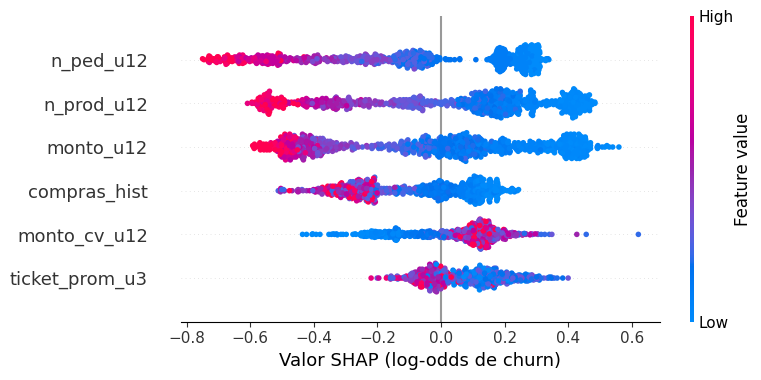

In [5]:
shap.summary_plot(valores_shap, X, show=False)
plt.xlabel("Valor SHAP (log-odds de churn)")
plt.savefig("../img/shap_v2_resumen.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Dependencia

El gráfico de resumen muestra la dirección; este muestra la **forma** de la relación. Para cada variable, cada punto es una vendedora: en el eje horizontal el valor de la variable y en el vertical su aporte SHAP.

Permite ver, por ejemplo, si el riesgo baja de forma pareja con más pedidos o si deja de bajar a partir de cierto número. El eje horizontal se recorta al percentil 99 para que unos pocos valores extremos no aplasten el gráfico.

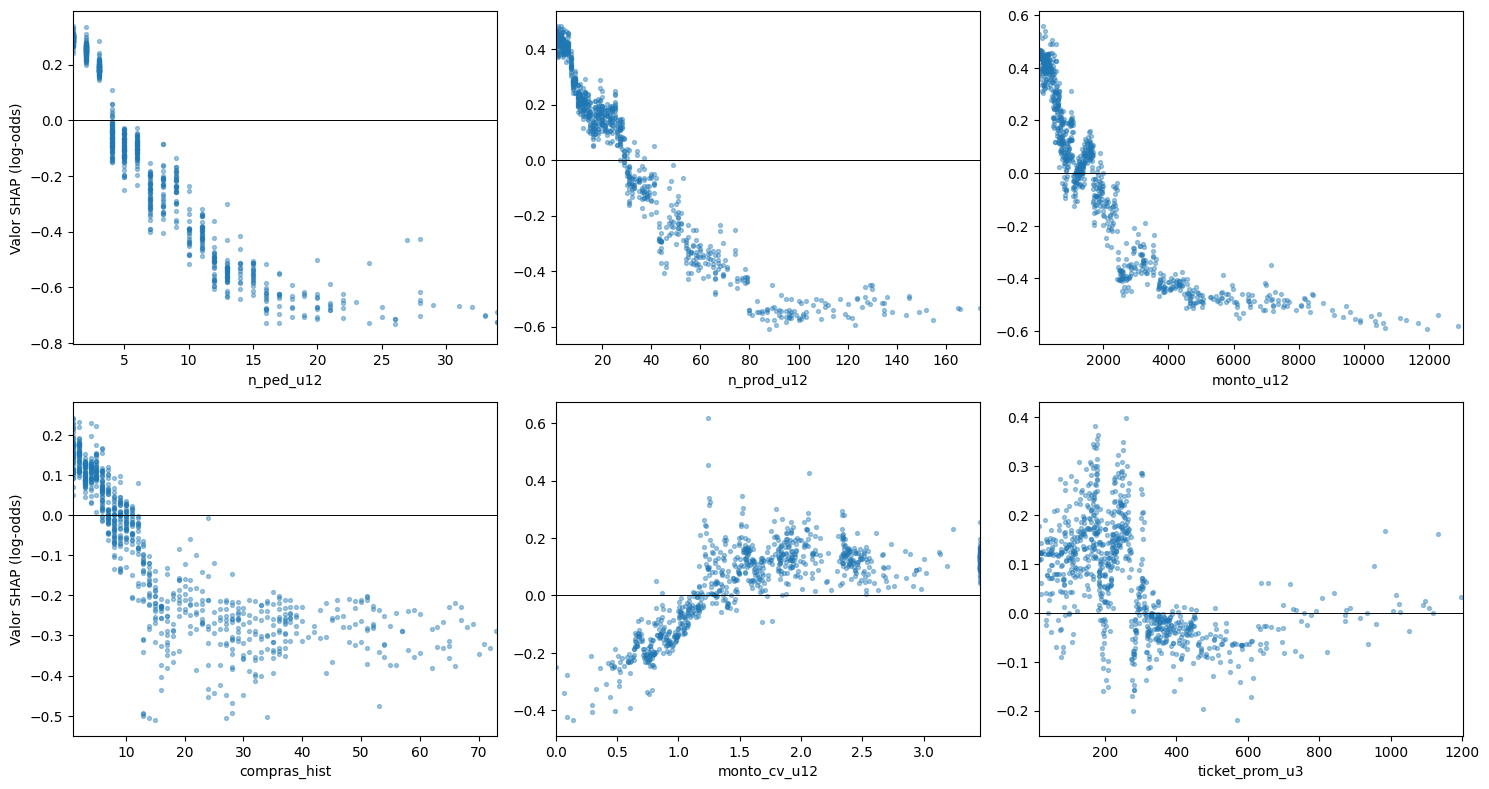

In [6]:
figura, ejes = plt.subplots(2, 3, figsize=(15, 8))
for eje, variable in zip(ejes.flat, ranking.index):
    eje.scatter(X[variable], valores_shap[:, variables.index(variable)], s=8, alpha=0.4)
    eje.axhline(0, color="k", lw=0.7)
    eje.set_xlim(X[variable].min(), X[variable].quantile(0.99))
    eje.set_xlabel(variable)
for eje in ejes[:, 0]:
    eje.set_ylabel("Valor SHAP (log-odds)")
figura.tight_layout()
figura.savefig("../img/shap_v2_dependencia.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Casos locales

Elegimos tres vendedoras del OOT según su probabilidad predicha: la más cercana al percentil 5 (riesgo bajo), al 50 (medio) y al 95 (alto). No se muestra su `id_vendedor`.

Cada gráfico parte del valor base y muestra cómo cada variable empuja la predicción: las barras **rojas** suben el riesgo y las **azules** lo bajan, hasta llegar a la probabilidad final de esa vendedora.

La tabla resume los tres casos: para cada variable, su valor y, entre paréntesis, su SHAP en log-odds.

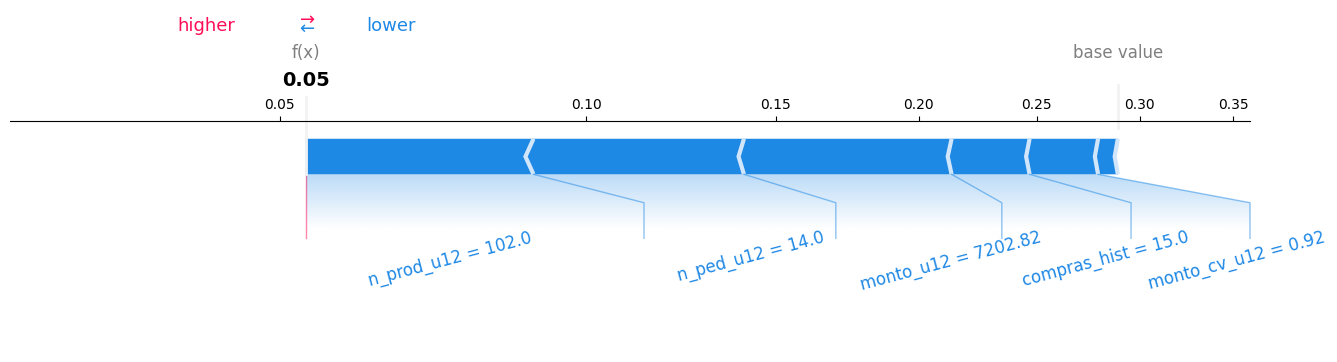

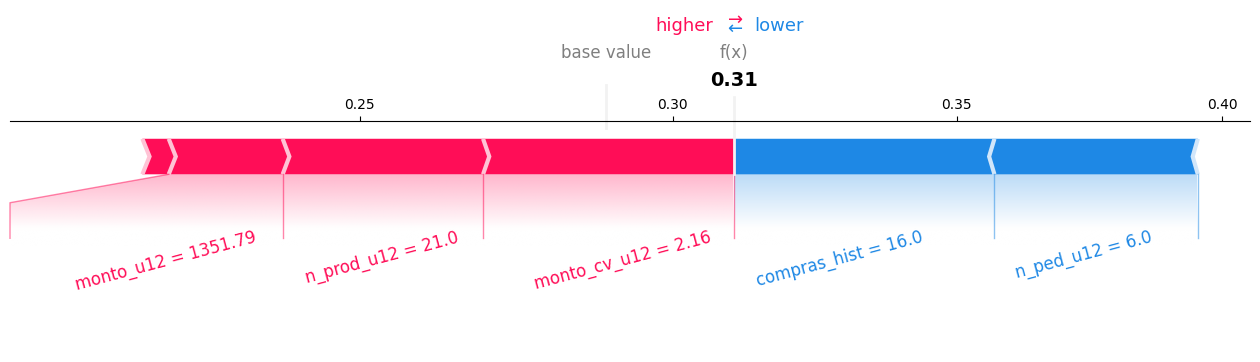

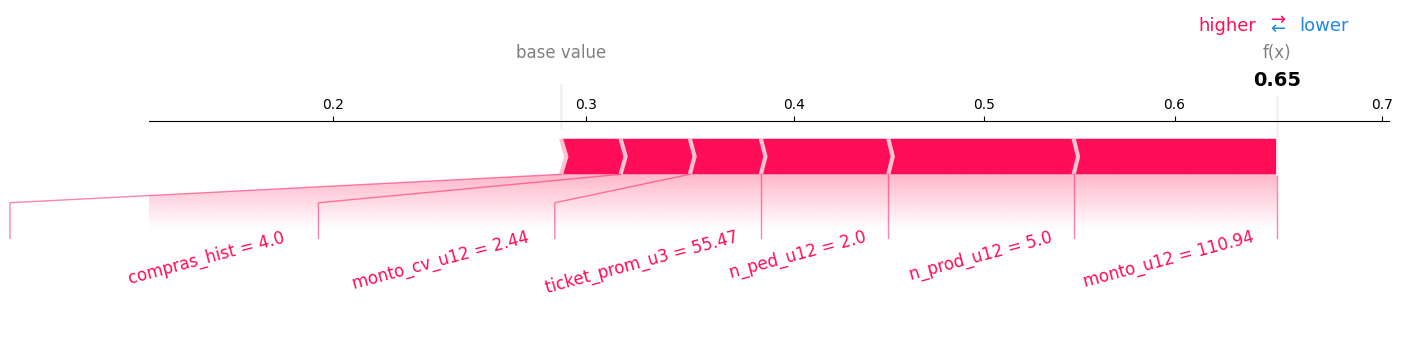

,probabilidad,n_ped_u12,n_prod_u12,monto_u12,compras_hist,monto_cv_u12,ticket_prom_u3
bajo,0.05,14.00 (-0.51),102.00 (-0.56),7202.82 (-0.51),15.00 (-0.19),0.92 (-0.17),521.06 (-0.05)
medio,0.31,6.00 (-0.16),21.00 (+0.16),1351.79 (+0.09),16.00 (-0.21),2.16 (+0.20),199.97 (+0.02)
alto,0.65,2.00 (+0.27),5.00 (+0.39),110.94 (+0.43),4.00 (+0.13),2.44 (+0.15),55.47 (+0.15)


In [7]:
filas_locales = {}
casos = {"bajo": 0.05, "medio": 0.50, "alto": 0.95}
for caso, cuantil in casos.items():
    probabilidad_objetivo = np.quantile(probabilidades, cuantil)
    i = int(np.abs(probabilidades - probabilidad_objetivo).argmin())
    shap.force_plot(valor_base, valores_shap[i], X.iloc[i].round(2), link="logit",
                    matplotlib=True, show=False, figsize=(16, 3), text_rotation=15)
    # con eje logit, shap puede dejar el límite inferior < 0 y la figura sale en blanco
    eje = plt.gca()
    eje.set_xlim(max(eje.get_xlim()[0], min(probabilidades[i], probabilidad_base) / 2), eje.get_xlim()[1])
    plt.savefig(f"../img/shap_v2_local_{caso}.png", dpi=200, bbox_inches="tight")
    plt.show()
    filas_locales[caso] = {
        "probabilidad": f"{probabilidades[i]:.2f}",
        **{
            variable: f"{X[variable].iat[i]:.2f} ({valores_shap[i, posicion]:+.2f})"
            for posicion, variable in enumerate(variables)
        },
    }
tabla_local = pd.DataFrame(filas_locales).T[["probabilidad", *ranking.index]]
display(tabla_local)

## 6. Reporte

Escribimos `reports/interpretacion_v2.md` con las tablas de esta ejecución y las rutas de las figuras.

In [8]:
reporte = f'''# Interpretación v2

Modelo: {configuracion["nombre"]} (experimento {experimento}), explicado sobre el OOT
({datos_oot["mes_obs"].min():%Y-%m} → {datos_oot["mes_obs"].max():%Y-%m}, {len(datos_oot)} filas).
AUC OOT del modelo explicado: {auc:.4f} (registrado en 05: {auc_registrado:.4f}).

## Método

TreeSHAP en log-odds. Valor base: {probabilidad_base:.3f} en probabilidad. Error máximo de exactitud: {error:.1e}.

## Importancia global

{ranking.round(4).to_markdown()}

`rho_valor_shap` > 0: valores altos de la variable elevan el riesgo; < 0: lo reducen.
Spearman entre el ranking SHAP y el de permutación de la fase 03: {rho_rankings:.2f}.

## Casos locales (valor de la variable y SHAP en log-odds)

{tabla_local.T.to_markdown()}

## Figuras

`img/shap_v2_resumen.png`, `img/shap_v2_dependencia.png`, `img/shap_v2_local_bajo.png`,
`img/shap_v2_local_medio.png`, `img/shap_v2_local_alto.png`.
'''
Path("../reports/interpretacion_v2.md").write_text(reporte, encoding="utf-8")
print("-> reports/interpretacion_v2.md")

-> reports/interpretacion_v2.md
